# Experimento A: warm starts greedy para TTAP

Este notebook **resuelve el MILP**. Compara HiGHS sin solución inicial, con
Greedy Benefit y con Greedy Density sobre las mismas instancias.

Ejecuta las celdas en orden. El modo inicial es un piloto de 20 tareas y una
semilla a 1, 5, 15 y 60 segundos. Para las 30 réplicas, cambia `MODE` a `full`
después de comprobar el piloto. Usa una carpeta persistente y un equipo estable
para la corrida completa; una sesión temporal de Colab puede interrumpirse.

Los módulos tienen una revisión y hashes fijados. Las salidas se guardan
localmente; el notebook no publica resultados en GitHub.

La primera celda usa una carpeta aislada con los módulos verificados. Si encuentra archivos locales de otra versión, descarga los correctos sin reemplazar los del proyecto. También admite los finales de línea de Windows. Después de actualizar este notebook, reinicia el kernel antes de ejecutar todas las celdas.


In [1]:
from pathlib import Path
import hashlib, importlib.util, json, subprocess, sys
from urllib.request import urlopen

RUNTIME_REVISION = 'fe68f9c4f5803b5bb7a17860b316f11ba351fd4f'
EXPECTED_SHA256 = {
    "frozen_generator_A.py": "d1eada7a7557203598f165be50b60faa4e9ef5e572bd64327d430848559841a6",
    "frozen_generator_B.py": "c33fbb583bceb3582f968f219abc8f5d1b4c5aaf17fa5ac8801cf66c32570297",
    "frozen_ttap_core.py": "d2d022eaf39cf91ab0d68eba3d95c131a2f90b6408d8e32472e29dc331b114a5",
    "ttap_warm_start.py": "96a9dc50863b7bb41ef34359cf4cf6cd143880cfd14a9970044396620d0405f6",
    "objective_profiles.py": "a655b2368b94b96d366fb3919e4300e0d8715efb5c2c88b2b00bbb8564b0eafe",
    "study_runner.py": "e02a59f2819730de6e728edbf13e02a630839ee6113e57f46060989ae6bf15bd",
    "study_analysis.py": "a673fdece4141fec6de81f98c3e955d962e6d415b71097bd8aec6d57ab3bafc4",
    "figure5_and_analysis.py": "8b611fa972678f051710c89484935a3eb84d26409c694c67e6bddd16f5757321",
    "public_sources.py": "4e1a545646f1ba46bf5a78f0930f39fac318f7ac304fe3874f41c2305ac36f1e",
    "talcahuano_three_methods.py": "ecabb5c3e4ba6af98a35dc4845a840891e0f6b7dacb8bfa0bfdbd44fe1c69d9d",
    "ablation_recovery.py": "e41a7a35efce97ada50c65493d7cafeabc47564e5263a9d8de3de7918331fc97",
    "requirements_execution.txt": "37b0105f36958ae5a61e8b2628f96339e1c9f9eff1306eee3748357d63766876"
}

def _ttap_canonical_bytes(content):
    # Git may check out text with CRLF on Windows. No other text is discarded.
    return content.replace(b'\r\n', b'\n')


def _ttap_prepare_runtime(revision, expected_hashes, *, root=None, opener=None):
    import tempfile

    root = Path.cwd() if root is None else Path(root)
    opener = urlopen if opener is None else opener
    signature = hashlib.sha256(
        json.dumps(expected_hashes, sort_keys=True).encode('utf-8')
    ).hexdigest()[:12]
    runtime = root / ('ttap_runtime_' + revision[:10] + '_' + signature)
    runtime.mkdir(parents=True, exist_ok=True)
    candidates = [root / 'TTAP_WarmStart', root / 'Resuelto_Paper' / 'TTAP_WarmStart',
                  root, root / ('ttap_runtime_' + revision[:10])]
    base = ('https://raw.githubusercontent.com/educarrascov/DISC_TESIS/'
            + revision + '/Resuelto_Paper/TTAP_WarmStart/')
    counts = {'cache': 0, 'local': 0, 'download': 0}

    def matching_bytes(path, expected):
        if not path.is_file():
            return None
        content = _ttap_canonical_bytes(path.read_bytes())
        return content if hashlib.sha256(content).hexdigest() == expected else None

    for name, expected in expected_hashes.items():
        path = runtime / name
        content = matching_bytes(path, expected)
        if content is not None:
            counts['cache'] += 1
            # Files written here always use LF, including a cache copied from Windows.
            if path.read_bytes() == content:
                continue
        else:
            for candidate in candidates:
                content = matching_bytes(candidate / name, expected)
                if content is not None:
                    counts['local'] += 1
                    break
            if content is None:
                try:
                    with opener(base + name, timeout=90) as response:
                        content = _ttap_canonical_bytes(response.read())
                except OSError as exc:
                    raise RuntimeError(
                        'No se pudo descargar ' + name + ' de la revisión ' + revision
                        + '. Comprueba la conexión y vuelve a ejecutar esta celda. '
                        + 'Los archivos de tu proyecto no se han modificado.'
                    ) from exc
                if hashlib.sha256(content).hexdigest() != expected:
                    raise RuntimeError('La descarga no coincide con la revisión fijada: '
                                       + name + '. No se ejecutará ese archivo.')
                counts['download'] += 1

        temporary = None
        try:
            with tempfile.NamedTemporaryFile(dir=runtime, prefix=name + '.',
                                             suffix='.tmp', delete=False) as handle:
                temporary = Path(handle.name)
                handle.write(content)
            temporary.replace(path)
        finally:
            if temporary is not None and temporary.exists():
                temporary.unlink()

    print('Fuentes verificadas:', counts)
    return runtime.resolve()


RUNTIME = _ttap_prepare_runtime(RUNTIME_REVISION, EXPECTED_SHA256)
for name in EXPECTED_SHA256:
    if not name.endswith('.py'):
        continue
    loaded = sys.modules.get(name[:-3])
    if loaded is not None:
        location = getattr(loaded, '__file__', None)
        if location is None or Path(location).resolve() != RUNTIME / name:
            raise RuntimeError(
                'Hay módulos TTAP de otra carpeta cargados en memoria. '
                'Reinicia el kernel (Kernel > Restart) y ejecuta desde la primera celda.'
            )


missing_science = [m for m in ['numpy', 'scipy', 'pandas', 'matplotlib']
                   if importlib.util.find_spec(m) is None]
if missing_science:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-r', str(RUNTIME / 'requirements_execution.txt')], check=True)
elif importlib.util.find_spec('highspy') is None:
    subprocess.run([sys.executable, '-m', 'pip', 'install', 'highspy==1.11.0'], check=True)
sys.path.insert(0, str(RUNTIME))
import highspy
if highspy.Highs().version() != '1.11.0':
    raise RuntimeError('Use highspy==1.11.0 and restart the kernel before the study.')
from IPython.display import display, Image
from objective_profiles import ObjectiveSpec, professor_examples
from study_runner import configuration, run_study
from study_analysis import export_report
print('Verified runtime:', RUNTIME_REVISION)
print('Local modules:', RUNTIME)


Fuentes verificadas: {'cache': 12, 'local': 0, 'download': 0}
Verified runtime: fe68f9c4f5803b5bb7a17860b316f11ba351fd4f
Local modules: /Users/educarrascovidal/Documentos/GitHub/Tesis_Doctoral/DISC_TESIS/Resuelto_Paper/ttap_runtime_fe68f9c4f5_6cd64fa67f6d


## Fijar el objetivo antes de resolver

`multidimensional` cuenta las tres cantidades como outputs distintos: pacientes,
personas no médicas y cargo. No se cuentan dos veces las mismas personas ni
se interpreta el cargo como su peso corporal. `primary` reproduce el objetivo
anterior: un propósito principal y requisitos auxiliares de apoyo.

En el primer modo, el valor potencial es
\(\phi_i=\lambda_m m_i/R_m+\lambda_p p_i/R_p+\lambda_q q_i/R_q\).
La satisfacción temporal y las restricciones se mantienen. Los pesos son
compensatorios y las referencias son escalas del generador. Un objetivo
distinto requiere referencias óptimas nuevas.


In [2]:
EXPERIMENT = 'A'
MODE = 'pilot'  # smoke: 1 s; pilot: 20 tareas/semilla 1; screen: 3 semillas; full: 30 semillas
OBJECTIVE_MODE = 'multidimensional'  # o 'primary'
WEIGHTS = {'medical': 2.0, 'personnel': 1.5, 'cargo': 1.0}
REFERENCES = {'medical': 3.0, 'personnel': 3.0, 'cargo': 500.0}
OUTPUT_ROOT = Path.cwd() / 'ttap_runs'  # Para full, usar almacenamiento persistente.
RESUME = True
RUN_REFERENCES = MODE == 'full' and OBJECTIVE_MODE == 'multidimensional'

spec = ObjectiveSpec(OBJECTIVE_MODE, WEIGHTS, REFERENCES)
config = configuration(EXPERIMENT, MODE, spec)
RUN_DIR = OUTPUT_ROOT / (EXPERIMENT + '_' + MODE + '_' + config.fingerprint[:12])
print('Objective:', spec.as_dict())
print('Configuration:', config.as_dict())
print('Output:', RUN_DIR)
print('Nominal workload:', config.workload())
print('Long reference phase enabled:', RUN_REFERENCES)
if spec.mode == 'multidimensional':
    print('Illustrative task values before common normalization:', professor_examples(spec))


Objective: {'schema': 'ttap-value-v2', 'mode': 'multidimensional', 'weights': {'medical': 2.0, 'personnel': 1.5, 'cargo': 1.0}, 'references': {'medical': 3.0, 'personnel': 3.0, 'cargo': 500.0}, 'semantics': 'distinct-medical-nonmedical-cargo-outputs'}
Configuration: {'experiment': 'A', 'tasks': [20], 'seeds': [1], 'budgets': [1.0, 5.0, 15.0, 60.0], 'reference_budgets': [600.0], 'objective': {'schema': 'ttap-value-v2', 'mode': 'multidimensional', 'weights': {'medical': 2.0, 'personnel': 1.5, 'cargo': 1.0}, 'references': {'medical': 3.0, 'personnel': 3.0, 'cargo': 500.0}, 'semantics': 'distinct-medical-nonmedical-cargo-outputs'}, 'threads': 1, 'solver_seed': 0, 'mip_rel_gap': 1e-06, 'trace': True}
Output: /Users/educarrascovidal/Documentos/GitHub/Tesis_Doctoral/DISC_TESIS/Resuelto_Paper/ttap_runs/A_pilot_000d5e561542
Nominal workload: {'instances': 1, 'warm_solver_runs': 12, 'reference_solver_runs': 1, 'nominal_warm_solver_hours': 0.0675, 'nominal_reference_solver_hours': 0.1666666666666

## Resolver los tres tratamientos

Cada start se convierte en un vector binario completo y se valida contra las
restricciones. HiGHS puede cambiarlo. La matriz y los parámetros son iguales
en los tres tratamientos; cada presupuesto inicia una búsqueda nueva.

La celda guarda checkpoints después de cada job. Para reanudar, conserva la
misma carpeta, configuración, fuentes y entorno. El manifiesto impide mezclar
versiones. La disponibilidad del plan greedy no demuestra una mejora del solver.


In [3]:
results = run_study(config, RUN_DIR, phase='warm', resume=RESUME)
cols = ['Scenario', 'Method', 'Normalized Mission Value', 'Warm Start Submitted',
        'Warm Start Value', 'Solver Has Incumbent', 'Optimal Certified',
        'Improvement Over Supplied Plan', 'End-to-end sec']
display(results[[c for c in cols if c in results]])


A4x4_T20_S1: build multidimensional MILP (warm)
  29,318 variables; 11,620 constraints
  HiGHS-1s-GBStart: value=0.429230; solver plan=True; certified=False
  HiGHS-1s-GDStart: value=0.432569; solver plan=True; certified=False
  HiGHS-1s-Cold: value=nan; solver plan=False; certified=False
  HiGHS-5s-GBStart: value=0.429230; solver plan=True; certified=False
  HiGHS-5s-GDStart: value=0.432569; solver plan=True; certified=False
  HiGHS-5s-Cold: value=nan; solver plan=False; certified=False
  HiGHS-15s-GBStart: value=0.552077; solver plan=True; certified=True
  HiGHS-15s-GDStart: value=0.552077; solver plan=True; certified=True
  HiGHS-15s-Cold: value=0.552077; solver plan=True; certified=True
  HiGHS-60s-GBStart: value=0.552077; solver plan=True; certified=True
  HiGHS-60s-GDStart: value=0.552077; solver plan=True; certified=True
  HiGHS-60s-Cold: value=0.552077; solver plan=True; certified=True


,Scenario,Method,Normalized Mission Value,Warm Start Submitted,Warm Start Value,Solver Has Incumbent,Optimal Certified,Improvement Over Supplied Plan,End-to-end sec
0,A4x4_T20_S1,Greedy-Benefit,0.429230,NaN,NaN,NaN,False,NaN,0.019914
1,A4x4_T20_S1,Greedy-Density-Operational,0.432569,NaN,NaN,NaN,False,NaN,0.001004
2,A4x4_T20_S1,HiGHS-1s-GBStart,0.429230,True,0.429230,True,False,0.000000,1.318418
3,A4x4_T20_S1,HiGHS-1s-GDStart,0.432569,True,0.432569,True,False,0.000000,1.274571
4,A4x4_T20_S1,HiGHS-1s-Cold,NaN,False,NaN,False,False,NaN,1.890832
5,A4x4_T20_S1,HiGHS-5s-GBStart,0.429230,True,0.429230,True,False,0.000000,5.984670
6,A4x4_T20_S1,HiGHS-5s-GDStart,0.432569,True,0.432569,True,False,0.000000,5.971752
7,A4x4_T20_S1,HiGHS-5s-Cold,NaN,False,NaN,False,False,NaN,5.811076
8,A4x4_T20_S1,HiGHS-15s-GBStart,0.552077,True,0.429230,True,True,0.122847,8.009622
9,A4x4_T20_S1,HiGHS-15s-GDStart,0.552077,True,0.432569,True,True,0.119508,7.888767


## Obtener referencias del mismo objetivo

La fase larga usa cold a 600 s en A y a 600/1800 s en B. Se ejecuta después
de las corridas cortas; sus soluciones no se entregan como starts.
En un piloto se deja desactivada. Puede activarse después con la misma
configuración y carpeta. Si una instancia no certifica, su distancia al óptimo
queda desconocida. El modo histórico sin cambios puede usar sus referencias
publicadas, verificadas contra el commit base.


In [4]:
if RUN_REFERENCES:
    results = run_study(config, RUN_DIR, phase='reference', resume=RESUME)
else:
    print('No long reference jobs launched. Unknown optima remain unknown.')


No long reference jobs launched. Unknown optima remain unknown.


## Examinar calidad y aporte de la inyección

La primera figura muestra los indicadores de presupuesto. La segunda distingue
el beneficio ganado sobre el greedy del beneficio de inyectarlo, comparando
con cold que conserva el mismo greedy como respaldo externo. Se retienen
diferencias negativas. Los CSV mantienen los tamaños muestrales y los resultados
por cantidad de tareas; no hay que interpretar el agregado como 150 réplicas
independientes. La traza ilustra una sola instancia.


,Configuration,Start Method,Time Limit sec,n,solver_incumbents,available_plans,certified,mean_solver_incumbent,median_solver_incumbent,mean_available_value,n_known_optima,n_known_incumbent_gaps,mean_solver_shortfall_pct,median_solver_shortfall_pct,mean_available_shortfall_pct,mean_measured_seconds,solver_incumbents_pct,available_plans_pct,certified_pct
0,A,Cold,1.0,1,0,0,0,NaN,NaN,0.000000,1,0,NaN,NaN,100.000000,1.890832,0.0,0.0,0.0
1,A,Cold,5.0,1,0,0,0,NaN,NaN,0.000000,1,0,NaN,NaN,100.000000,5.811076,0.0,0.0,0.0
2,A,Cold,15.0,1,1,1,1,0.552077,0.552077,0.552077,1,1,0.000000,0.000000,0.000000,7.783525,100.0,100.0,100.0
3,A,Cold,60.0,1,1,1,1,0.552077,0.552077,0.552077,1,1,0.000000,0.000000,0.000000,8.136706,100.0,100.0,100.0
4,A,GBStart,1.0,1,1,1,0,0.429230,0.429230,0.429230,1,1,22.251860,22.251860,22.251860,1.318418,100.0,100.0,0.0
5,A,GBStart,5.0,1,1,1,0,0.429230,0.429230,0.429230,1,1,22.251860,22.251860,22.251860,5.984670,100.0,100.0,0.0
6,A,GBStart,15.0,1,1,1,1,0.552077,0.552077,0.552077,1,1,0.000000,0.000000,0.000000,8.009622,100.0,100.0,100.0
7,A,GBStart,60.0,1,1,1,1,0.552077,0.552077,0.552077,1,1,0.000000,0.000000,0.000000,7.747415,100.0,100.0,100.0
8,A,GDStart,1.0,1,1,1,0,0.432569,0.432569,0.432569,1,1,21.647034,21.647034,21.647034,1.274571,100.0,100.0,0.0
9,A,GDStart,5.0,1,1,1,0,0.432569,0.432569,0.432569,1,1,21.647034,21.647034,21.647034,5.971752,100.0,100.0,0.0


,Configuration,Start Method,Time Limit sec,n,mean_gain_over_greedy,median_gain_over_greedy,mean_injection_gain,median_injection_gain,improved_greedy,beat_cold_plus_greedy
0,A,GBStart,1.0,1,0.000000,0.000000,0.0,0.0,0,0
1,A,GBStart,5.0,1,0.000000,0.000000,0.0,0.0,0,0
2,A,GBStart,15.0,1,0.122847,0.122847,0.0,0.0,1,0
3,A,GBStart,60.0,1,0.122847,0.122847,0.0,0.0,1,0
4,A,GDStart,1.0,1,0.000000,0.000000,0.0,0.0,0,0
5,A,GDStart,5.0,1,0.000000,0.000000,0.0,0.0,0,0
6,A,GDStart,15.0,1,0.119508,0.119508,0.0,0.0,1,0
7,A,GDStart,60.0,1,0.119508,0.119508,0.0,0.0,1,0


Certified reference instances: 1


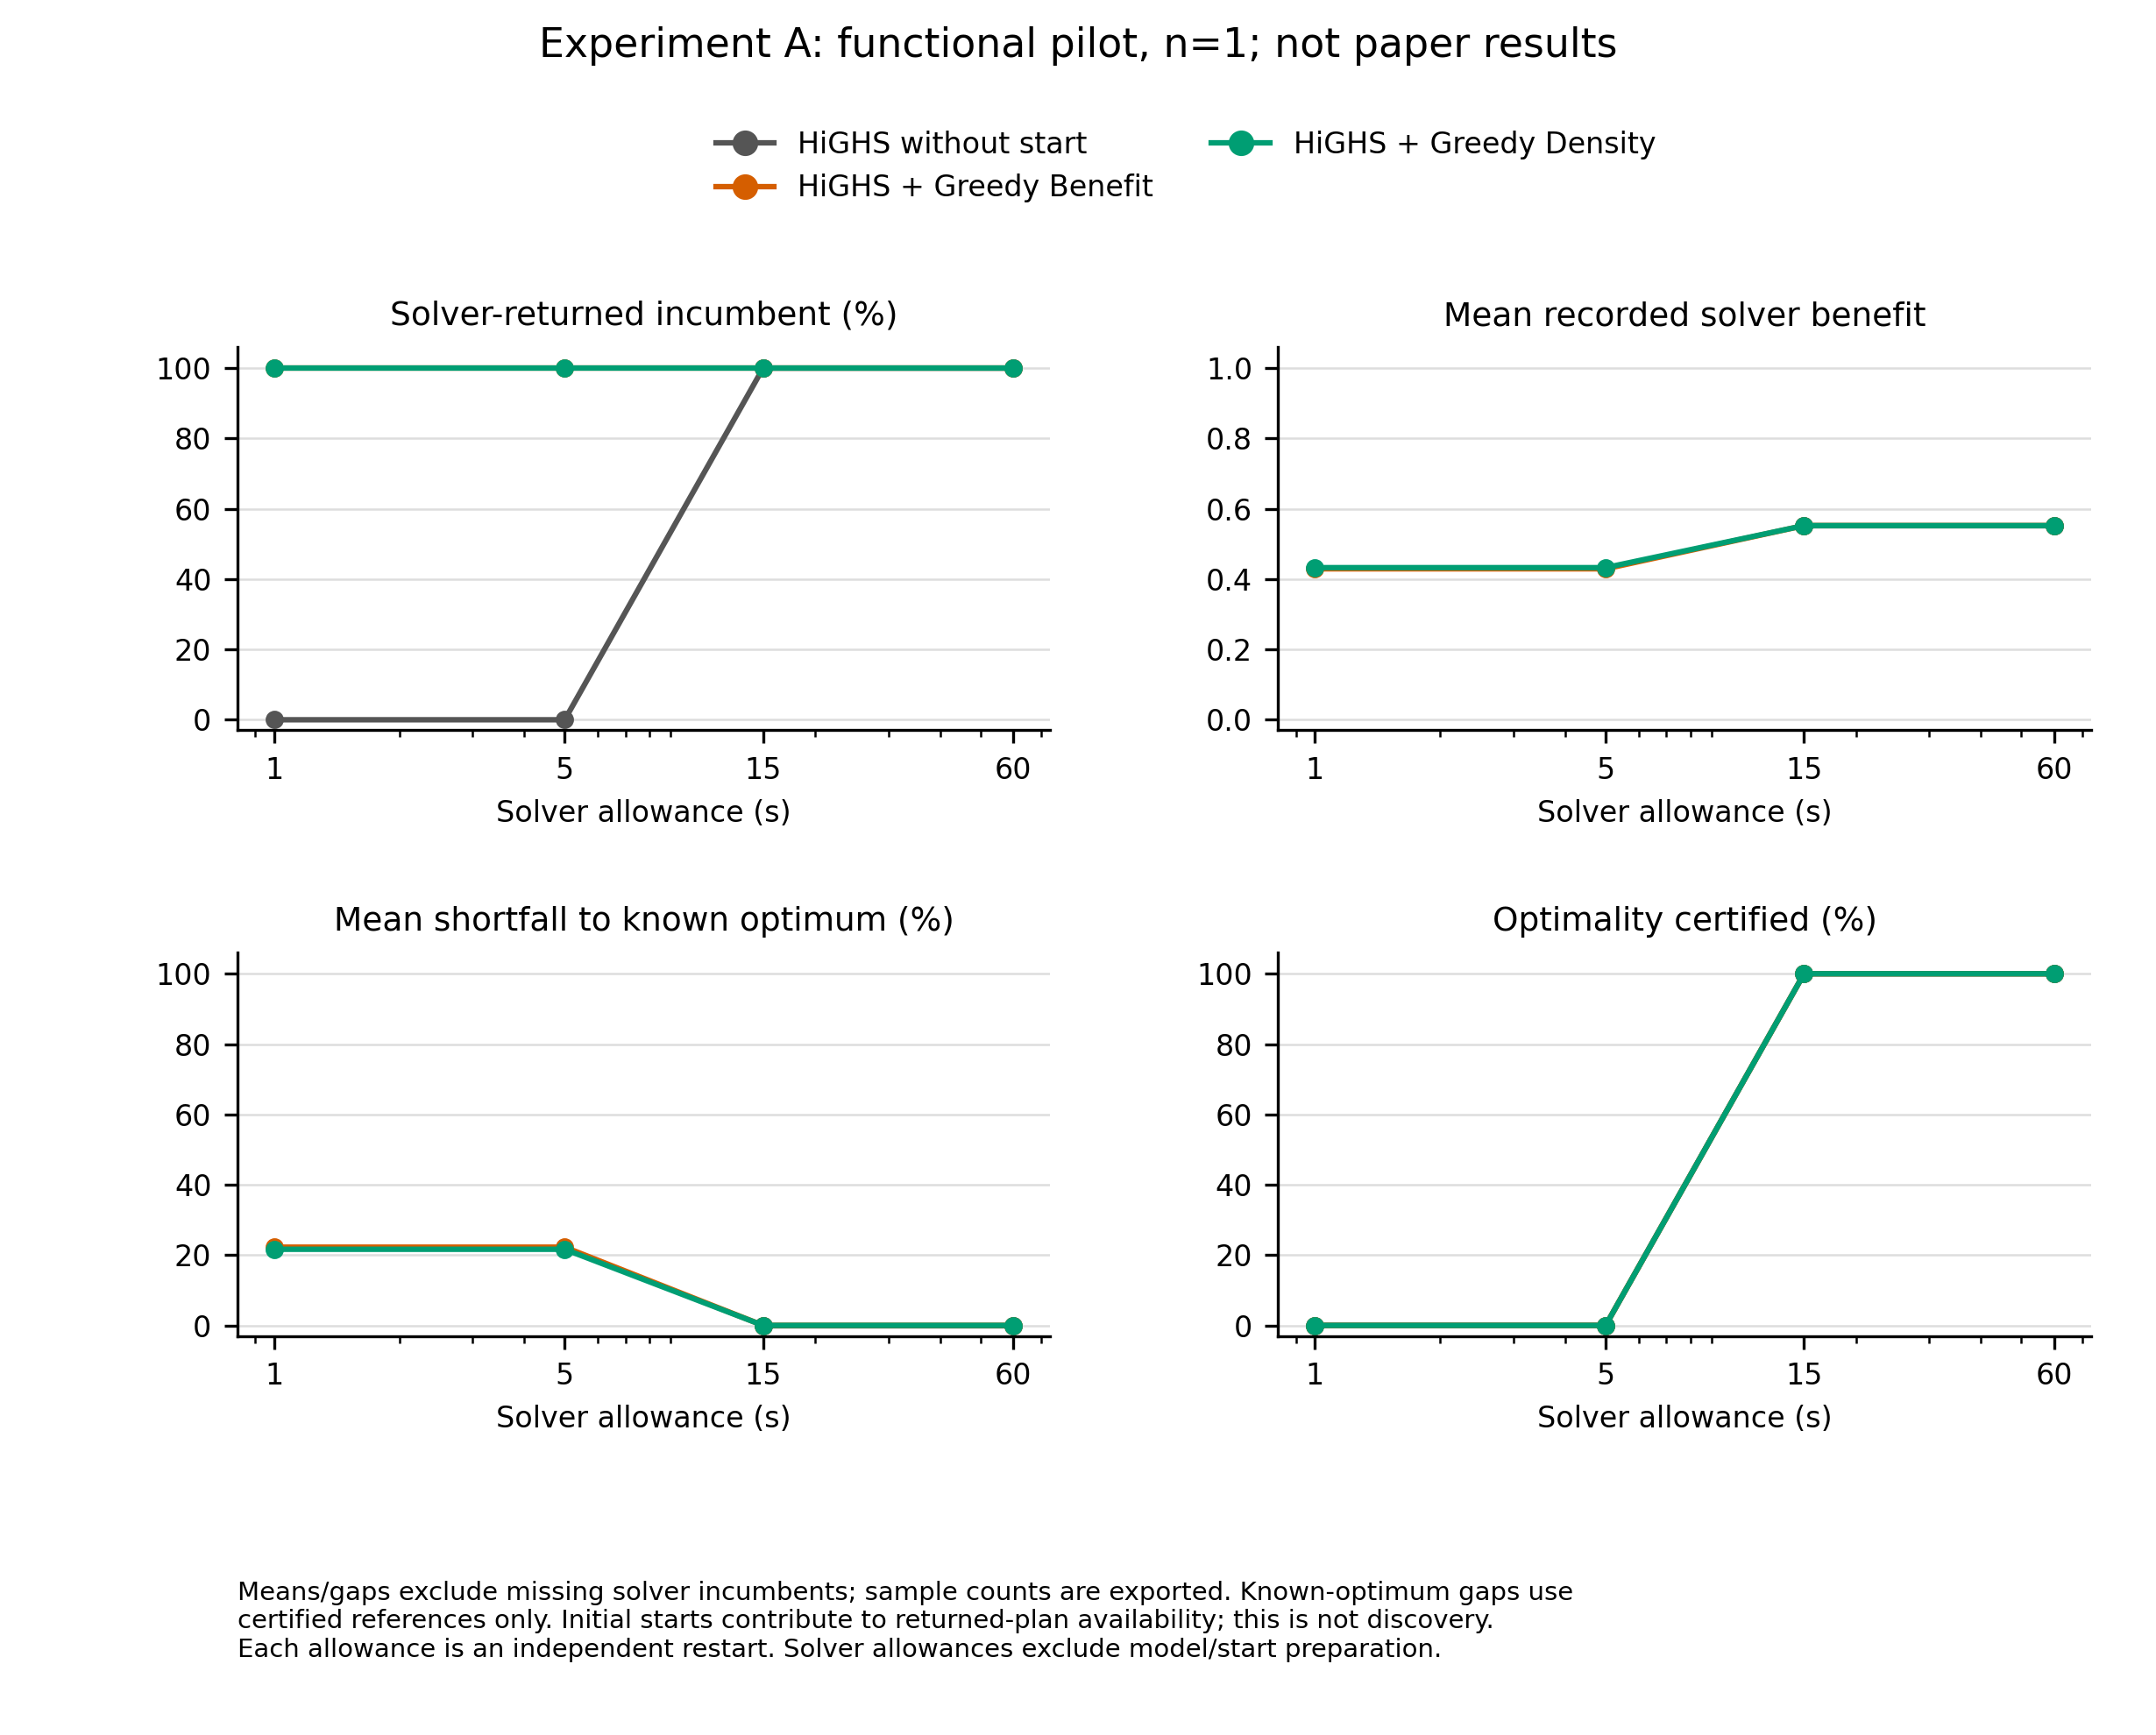

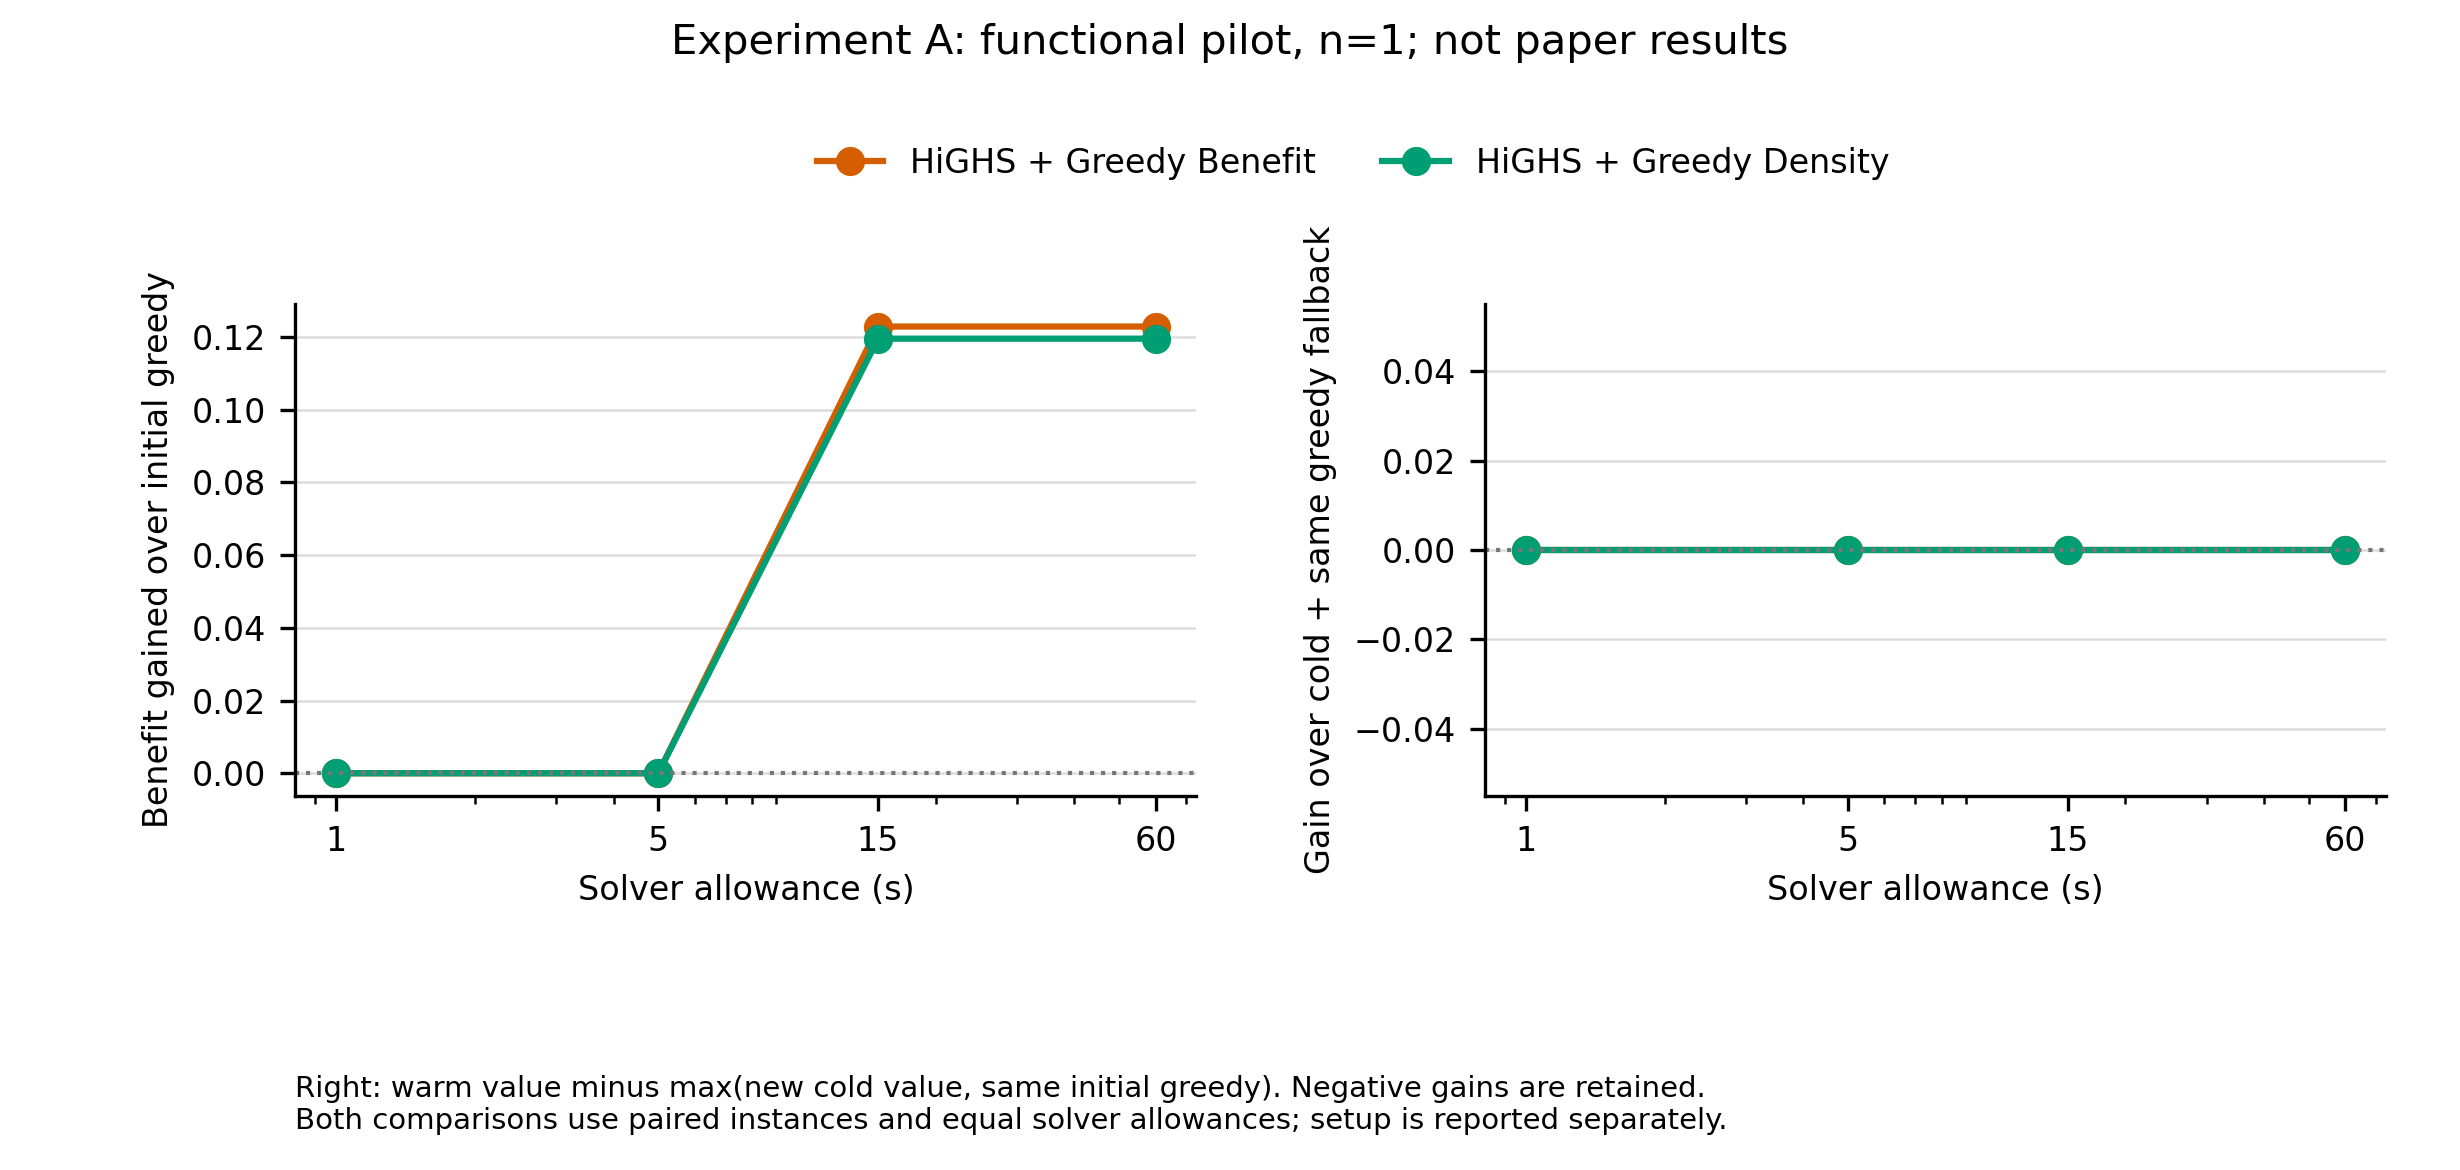

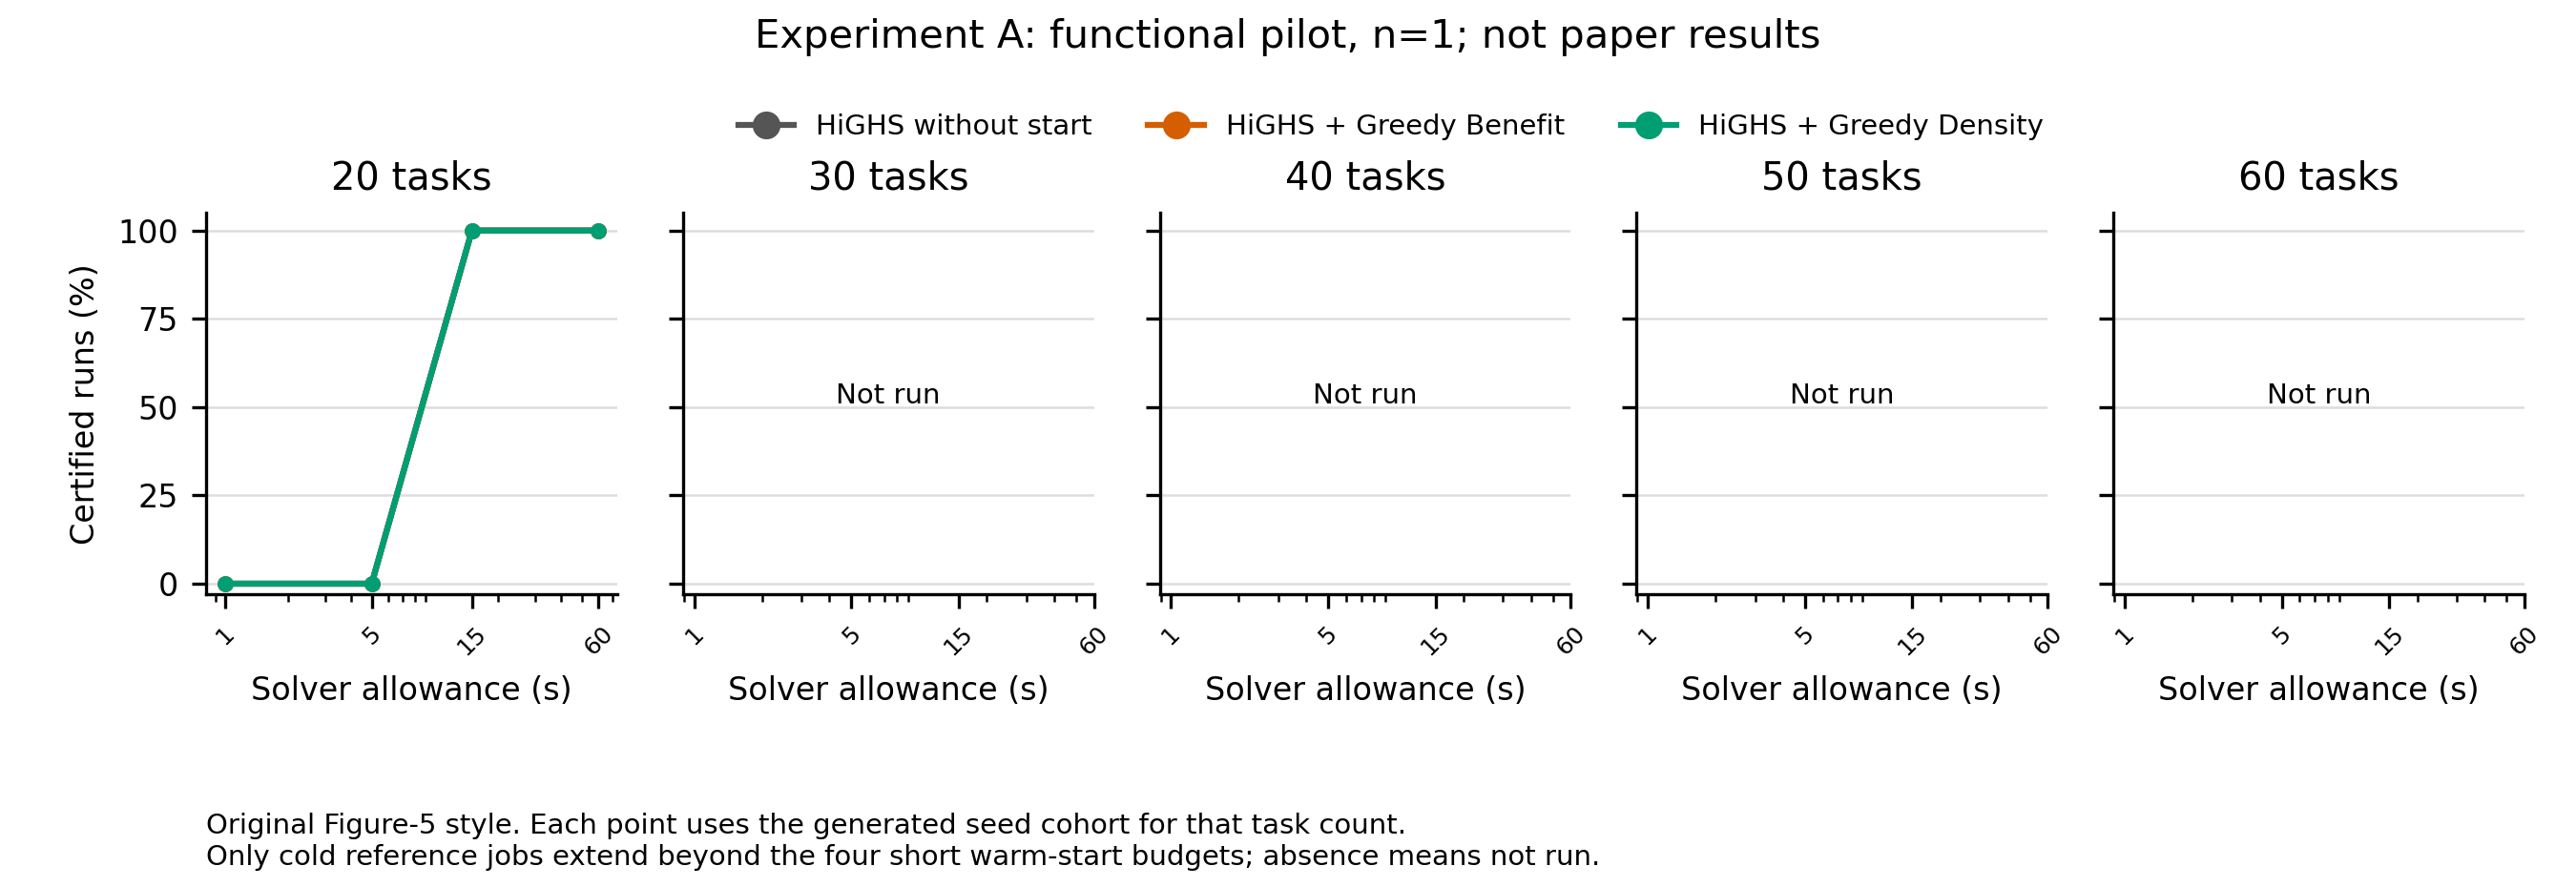

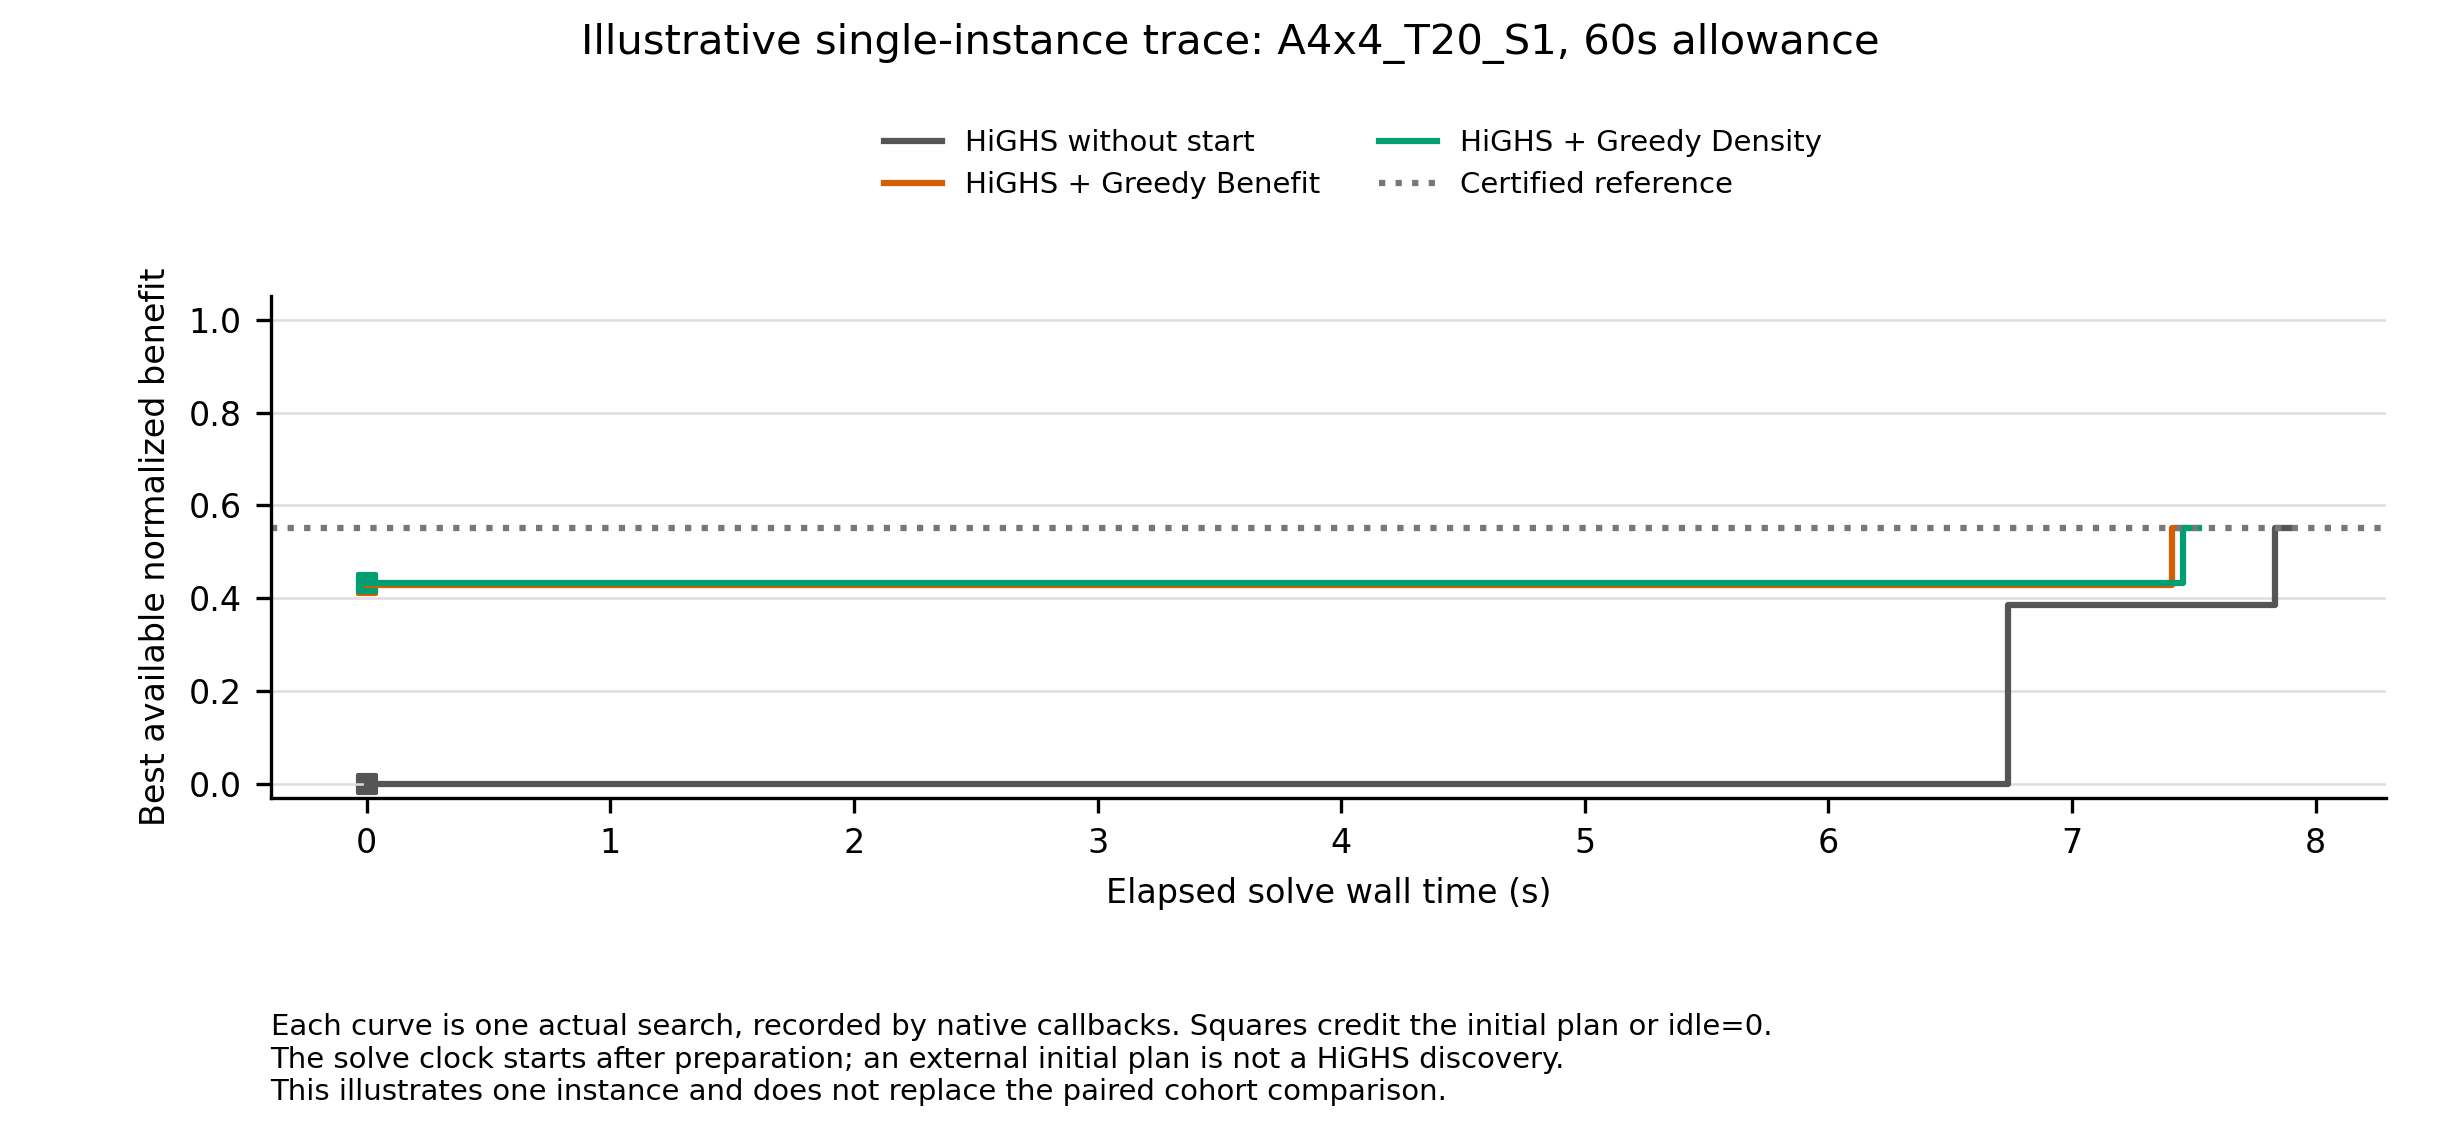

In [5]:
report = export_report(RUN_DIR, require_full=(MODE == 'full'))
display(report['quality'])
display(report['attribution'])
print('Certified reference instances:', len(report['references']))
for name in ['Figure_WarmStart_quality', 'Figure_WarmStart_attribution',
             'Figure_WarmStart_certification_by_tasks', 'Figure_WarmStart_trace_example']:
    path = report['figures'] / (name + '.png')
    if path.exists():
        display(Image(filename=str(path)))


## Figura 5 conjunta, cuando A y B estén terminados

La celda usa el mismo objetivo y modo para localizar la otra configuración.
Conserva el diseño de certificación por tamaño y exporta una tabla con
disponibilidad, valor del incumbent y diferencia al óptimo conocido.


In [6]:
BUILD_COMBINED_FIGURE = False
if BUILD_COMBINED_FIGURE:
    from study_analysis import export_combined_figure5
    other = 'B' if EXPERIMENT == 'A' else 'A'
    other_config = configuration(other, MODE, spec)
    other_dir = OUTPUT_ROOT / (other + '_' + MODE + '_' + other_config.fingerprint[:12])
    a_dir, b_dir = (RUN_DIR, other_dir) if EXPERIMENT == 'A' else (other_dir, RUN_DIR)
    table = export_combined_figure5(a_dir, b_dir, OUTPUT_ROOT / ('combined_' + MODE + '_' + spec.fingerprint[:12]))
    display(table)


## Chequeos opcionales, desactivados

La sensibilidad cambia los pesos manteniendo las instancias y referencias.
Comparar outputs físicos o reevaluar los planes con una utilidad común; los
objetivos de pesos distintos no representan la misma preferencia.
La ablación permite una sola salida por helicóptero para aislar el valor
de la recuperación repetida. Una diferencia óptima sólo se declara cuando
ambas corridas certifican; de otro modo se exportan cotas.


In [7]:
RUN_WEIGHT_SCREEN = False
RUN_RECOVERY_ABLATION = False
if RUN_WEIGHT_SCREEN:
    from study_runner import StudyConfig
    for weights in [{'medical': 1., 'personnel': 1., 'cargo': 1.},
                    {'medical': 2., 'personnel': 1.5, 'cargo': 1.},
                    {'medical': 6., 'personnel': 1.5, 'cargo': 1.}]:
        alternative = ObjectiveSpec(OBJECTIVE_MODE, weights, REFERENCES)
        check = StudyConfig(EXPERIMENT, tasks=(20, 40), seeds=(1, 2, 3), budgets=(60.,), objective=alternative)
        folder = OUTPUT_ROOT / ('weight_screen_' + EXPERIMENT + '_' + check.fingerprint[:12])
        run_study(check, folder, resume=RESUME)
        export_report(folder)
if RUN_RECOVERY_ABLATION:
    from ablation_recovery import compare_recovery
    table, interval = compare_recovery(OUTPUT_ROOT / ('one_sortie_' + EXPERIMENT + '_' + spec.fingerprint[:12]),
                                      experiment=EXPERIMENT, tasks=20, seed=1, spec=spec, solver_budget=600.)
    display(table)
    display(interval)
